In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving student_service_requests.csv to student_service_requests (2).csv
Uploaded files: ['student_service_requests (2).csv']


In [ ]:

import io

csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload the official CSV dataset.")

df = pd.read_csv(io.BytesIO(uploaded[csv_files[0]]))

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head(10))


Dataset loaded successfully!
Rows and columns: (400, 14)


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score
0,SR2026001,Certification,Student,2026-07-12,Email,Low,Registrar,1,Yes,3.0,3,Completed,No,1.0
1,SR2026002,IT Support,Student,2026-09-27,Portal,Normal,ICT Office,10,No,5.0,2,Completed,No,4.0
2,SR2026003,Certification,Student,2026-07-02,Portal,Low,Registrar,24,Yes,5.0,3,Completed,No,4.0
3,SR2026004,Enrollment Concern,Student,2026-04-15,Portal,Normal,Student Affairs,9,Yes,5.0,4,Completed,No,3.0
4,SR2026005,Certification,Student,2026-07-16,Portal,Normal,Registrar,20,No,8.0,3,Completed,No,2.0
5,SR2026006,Payment Assistance,Student,2026-06-11,Walk-in,Normal,Accounting Office,13,Yes,5.0,3,Completed,No,5.0
6,SR2026007,IT Support,Staff,2026-04-21,Email,Normal,ICT Office,6,Yes,3.0,2,Completed,No,5.0
7,SR2026008,Enrollment Concern,Student,2026-07-12,Email,High,Student Affairs,1,No,7.0,4,Completed,No,NaN
8,SR2026009,Records,Student,2026-07-31,Email,High,Registrar,8,Yes,3.0,3,Completed,No,5.0
9,SR2026010,Certification,Student,2026-06-14,Portal,High,Registrar,15,Yes,3.0,3,Completed,No,4.0


**Task 1: Dataset understanding**

In [ ]:

print("Dataset Shape:", df.shape)

display(df.head(10))

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:
    print(f"\nFrequency of {col}:")
    print(df[col].value_counts(dropna=False))


Dataset Shape: (400, 14)


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score
0,SR2026001,Certification,Student,2026-07-12,Email,Low,Registrar,1,Yes,3.0,3,Completed,No,1.0
1,SR2026002,IT Support,Student,2026-09-27,Portal,Normal,ICT Office,10,No,5.0,2,Completed,No,4.0
2,SR2026003,Certification,Student,2026-07-02,Portal,Low,Registrar,24,Yes,5.0,3,Completed,No,4.0
3,SR2026004,Enrollment Concern,Student,2026-04-15,Portal,Normal,Student Affairs,9,Yes,5.0,4,Completed,No,3.0
4,SR2026005,Certification,Student,2026-07-16,Portal,Normal,Registrar,20,No,8.0,3,Completed,No,2.0
5,SR2026006,Payment Assistance,Student,2026-06-11,Walk-in,Normal,Accounting Office,13,Yes,5.0,3,Completed,No,5.0
6,SR2026007,IT Support,Staff,2026-04-21,Email,Normal,ICT Office,6,Yes,3.0,2,Completed,No,5.0
7,SR2026008,Enrollment Concern,Student,2026-07-12,Email,High,Student Affairs,1,No,7.0,4,Completed,No,NaN
8,SR2026009,Records,Student,2026-07-31,Email,High,Registrar,8,Yes,3.0,3,Completed,No,5.0
9,SR2026010,Certification,Student,2026-06-14,Portal,High,Registrar,15,Yes,3.0,3,Completed,No,4.0



Column Names:
['Request_ID', 'Service_Type', 'Requester_Type', 'Submission_Date', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Queue_Length', 'Required_Documents_Complete', 'Processing_Days', 'SLA_Days', 'Status', 'Reopened', 'Satisfaction_Score']

Data Types:
Request_ID                      object
Service_Type                    object
Requester_Type                  object
Submission_Date                 object
Requested_Channel               object
Priority                        object
Assigned_Office                 object
Queue_Length                     int64
Required_Documents_Complete     object
Processing_Days                float64
SLA_Days                         int64
Status                          object
Reopened                        object
Satisfaction_Score             float64
dtype: object

Missing Values:
Request_ID                       0
Service_Type                     0
Requester_Type                   0
Submission_Date                  0
Requested_Cha

**Task 2: Identify predictors ug target**

In [ ]:

expected_columns = [
    "Request_ID",
    "Service_Type",
    "Requester_Type",
    "Submission_Date",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Queue_Length",
    "Required_Documents_Complete",
    "Processing_Days",
    "SLA_Days",
    "Status",
    "Reopened",
    "Satisfaction_Score"
]

print("Available columns:")
print(df.columns.tolist())

print("\nExpected columns missing from dataset:")
print([c for c in expected_columns if c not in df.columns])


Available columns:
['Request_ID', 'Service_Type', 'Requester_Type', 'Submission_Date', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Queue_Length', 'Required_Documents_Complete', 'Processing_Days', 'SLA_Days', 'Status', 'Reopened', 'Satisfaction_Score']

Expected columns missing from dataset:
[]


**Task 3: Explain how the data could be collected**

The student service request dataset could be collected programmatically from the university's online student-services portal using a secure API or a database connection. Each request record would contain its identifier, service type, submission date, priority, assigned office, queue length, and other relevant fields. The system should validate the data, restrict access to authorized personnel, and protect students' personal information. Historical records should be used according to university privacy and data-retention policies.

**Task 4: Data quality checking ug cleaning**

In [ ]:

clean_df = df.copy()
quality_log = []

def log_issue(issue, count, treatment):
    quality_log.append({
        "Issue": issue,
        "Count": int(count),
        "Treatment": treatment
    })

clean_df.columns = clean_df.columns.str.strip()

for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].apply(
        lambda x: " ".join(x.split()) if isinstance(x, str) else x
    )

for col, count in clean_df.isnull().sum().items():
    if count > 0:
        log_issue(
            f"Missing values in {col}",
            count,
            "Retain missing values unless a safe, justified treatment is available"
        )

if "Request_ID" in clean_df.columns:
    duplicate_count = clean_df["Request_ID"].duplicated().sum()

    log_issue(
        "Duplicate Request_ID",
        duplicate_count,
        "Keep the first occurrence; investigate duplicates before real deployment"
    )

    clean_df = clean_df.drop_duplicates(
        subset=["Request_ID"], keep="first"
    )

if "Submission_Date" in clean_df.columns:
    raw_dates = clean_df["Submission_Date"].copy()
    parsed_dates = pd.to_datetime(raw_dates, errors="coerce")

    invalid_dates = (
        raw_dates.notna()
        & raw_dates.astype(str).str.strip().ne("")
        & parsed_dates.isna()
    )

    log_issue(
        "Invalid Submission_Date",
        invalid_dates.sum(),
        "Convert invalid dates to missing; exclude from date-based analysis"
    )

    clean_df["Submission_Date"] = parsed_dates

numeric_cols = [
    "Queue_Length",
    "Processing_Days",
    "SLA_Days",
    "Satisfaction_Score"
]

for col in numeric_cols:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(
            clean_df[col], errors="coerce"
        )

        negative = clean_df[col] < 0
        count = negative.sum()

        log_issue(
            f"Negative values in {col}",
            count,
            "Replace invalid negative values with missing values"
        )

        clean_df.loc[negative, col] = np.nan

category_cols = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Required_Documents_Complete",
    "Status",
    "Reopened"
]

for col in category_cols:
    if col in clean_df.columns:
        values = clean_df[col].dropna().astype(str)
        canonical = {}

        for value in values.unique():
            key = value.strip().casefold()
            matching = values[
                values.str.strip().str.casefold() == key
            ]
            canonical[key] = matching.value_counts().idxmax()

        clean_df[col] = clean_df[col].apply(
            lambda x: canonical.get(x.strip().casefold(), x)
            if isinstance(x, str) else x
        )

quality_log_df = pd.DataFrame(quality_log)

display(quality_log_df)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)


,Issue,Count,Treatment
0,Missing values in Processing_Days,99,"Retain missing values unless a safe, justified..."
1,Missing values in Satisfaction_Score,143,"Retain missing values unless a safe, justified..."
2,Duplicate Request_ID,0,Keep the first occurrence; investigate duplica...
3,Invalid Submission_Date,0,Convert invalid dates to missing; exclude from...
4,Negative values in Queue_Length,0,Replace invalid negative values with missing v...
5,Negative values in Processing_Days,0,Replace invalid negative values with missing v...
6,Negative values in SLA_Days,0,Replace invalid negative values with missing v...
7,Negative values in Satisfaction_Score,0,Replace invalid negative values with missing v...


Original dataset shape: (400, 14)
Cleaned dataset shape: (400, 14)


In [ ]:

quality_log_df.to_csv("data_quality_log.csv", index=False)

print("Data quality log saved.")


Data quality log saved.


**Task 5: Feature engineering**

In [ ]:


clean_df["Submission_Weekday"] = (
    clean_df["Submission_Date"].dt.day_name()
)

def categorize_queue(value):
    if pd.isna(value):
        return np.nan
    elif value <= 5:
        return "Low"
    elif value <= 15:
        return "Medium"
    else:
        return "High"

clean_df["Queue_Category"] = clean_df["Queue_Length"].apply(
    categorize_queue
)

status = clean_df["Status"].astype("string").str.strip().str.casefold()

eligible = (
    status.eq("completed")
    & clean_df["Processing_Days"].notna()
    & clean_df["SLA_Days"].notna()
)

clean_df["SLA_Breached"] = np.nan

clean_df.loc[eligible, "SLA_Breached"] = (
    clean_df.loc[eligible, "Processing_Days"]
    > clean_df.loc[eligible, "SLA_Days"]
).astype(int)

clean_df.to_csv("student_service_requests_cleaned.csv", index=False)

model_df = clean_df.loc[eligible].copy()
model_df["SLA_Breached"] = model_df["SLA_Breached"].astype(int)

model_df.to_csv("sla_breach_labeled_records.csv", index=False)

print("All records:", len(clean_df))
print("Eligible completed records:", len(model_df))
print("\nTarget distribution:")

display(model_df["SLA_Breached"].value_counts().rename(
    index={0: "Not breached", 1: "Breached"}
))


All records: 400
Eligible completed records: 301

Target distribution:


,count
SLA_Breached,
Breached,213
Not breached,88


**Tasks 6–7: Exploratory Data Analysis (EDA)**

In [ ]:


service_counts = clean_df["Service_Type"].value_counts()

display(service_counts.rename("Request_Count").to_frame())

print("Most requested service type:")
print(service_counts.head(1))


,Request_Count
Service_Type,
Records,93
Certification,82
IT Support,79
Scholarship Inquiry,57
Payment Assistance,45
Enrollment Concern,44


Most requested service type:
Service_Type
Records    93
Name: count, dtype: int64


In [ ]:


office_stats = (
    model_df.groupby("Assigned_Office")["SLA_Breached"]
    .agg(Requests="count", Breaches="sum", Breach_Rate="mean")
    .sort_values("Breach_Rate", ascending=False)
)

office_stats["Breach_Rate_Percent"] = (
    office_stats["Breach_Rate"] * 100
).round(2)

display(office_stats)


,Requests,Breaches,Breach_Rate,Breach_Rate_Percent
Assigned_Office,,,,
ICT Office,53,41,0.773585,77.36
Registrar,137,100,0.729927,72.99
Accounting Office,28,20,0.714286,71.43
Scholarship Office,51,32,0.627451,62.75
Student Affairs,32,20,0.625000,62.50


In [ ]:


queue_stats = (
    model_df.groupby("Queue_Category")["SLA_Breached"]
    .agg(Requests="count", Breaches="sum", Breach_Rate="mean")
)

queue_stats["Breach_Rate_Percent"] = (
    queue_stats["Breach_Rate"] * 100
).round(2)

display(queue_stats)


,Requests,Breaches,Breach_Rate,Breach_Rate_Percent
Queue_Category,,,,
High,123,109,0.886179,88.62
Low,75,35,0.466667,46.67
Medium,103,69,0.669903,66.99


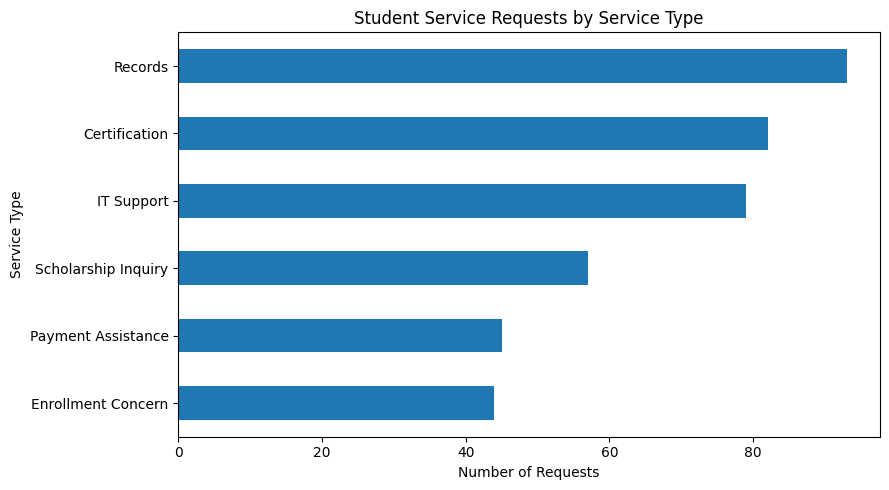

In [ ]:


service_counts.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Student Service Requests by Service Type")
plt.xlabel("Number of Requests")
plt.ylabel("Service Type")
plt.tight_layout()
plt.show()


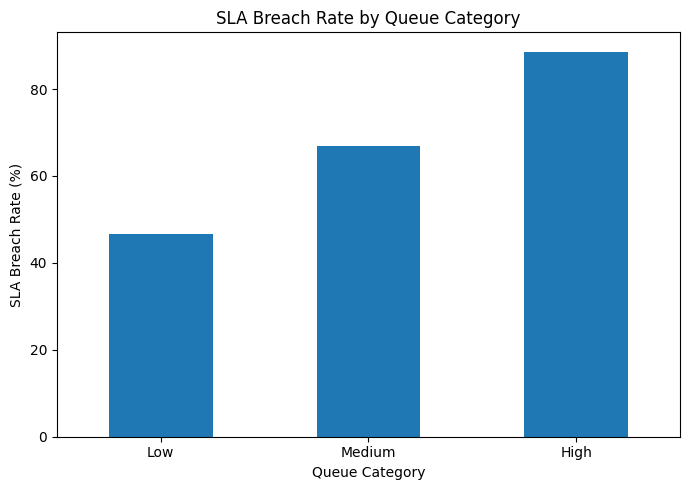

In [ ]:


queue_order = ["Low", "Medium", "High"]

rates = (
    model_df.groupby("Queue_Category")["SLA_Breached"]
    .mean()
    .reindex(queue_order) * 100
)

rates.plot(kind="bar", figsize=(7, 5))

plt.title("SLA Breach Rate by Queue Category")
plt.xlabel("Queue Category")
plt.ylabel("SLA Breach Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


T**asks 8–10: Decision Tree model**

In [ ]:


candidate_features = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Queue_Length",
    "Required_Documents_Complete",
    "SLA_Days",
    "Submission_Weekday",
    "Queue_Category"
]

features = [
    col for col in candidate_features
    if col in model_df.columns
]

X = model_df[features].copy()
y = model_df["SLA_Breached"].astype(int)

print("Predictor columns:")
print(features)

print("\nNumber of eligible records:", len(model_df))
print("\nTarget counts:")
print(y.value_counts())

if len(features) < 5:
    raise ValueError(
        "Need at least five valid submission-time predictors. "
        "Check the dataset column names."
    )

if y.nunique() != 2:
    raise ValueError(
        "The labeled dataset needs both breach classes (0 and 1)."
    )

if y.value_counts().min() < 2:
    raise ValueError(
        "There are too few examples in one target class "
        "for a stratified train/test split."
    )


Predictor columns:
['Service_Type', 'Requester_Type', 'Requested_Channel', 'Priority', 'Assigned_Office', 'Queue_Length', 'Required_Documents_Complete', 'SLA_Days', 'Submission_Weekday', 'Queue_Category']

Number of eligible records: 301

Target counts:
SLA_Breached
1    213
0     88
Name: count, dtype: int64


In [ ]:

from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier

categorical_features = X.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

model.fit(X_train, y_train)

print("Decision Tree training completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Decision Tree training completed!
Training records: 240
Testing records: 61


In [ ]:


y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    zero_division=0
))

results = {
    "Metric": [
        "Accuracy",
        "Precision (Breach = 1)",
        "Recall (Breach = 1)",
        "F1-score (Breach = 1)"
    ],
    "Decision Tree": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    ]
}

evaluation_df = pd.DataFrame(results)
display(evaluation_df.round(3))


Confusion Matrix:
[[ 8 10]
 [11 32]]

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.44      0.43        18
           1       0.76      0.74      0.75        43

    accuracy                           0.66        61
   macro avg       0.59      0.59      0.59        61
weighted avg       0.66      0.66      0.66        61



,Metric,Decision Tree
0,Accuracy,0.656
1,Precision (Breach = 1),0.762
2,Recall (Breach = 1),0.744
3,F1-score (Breach = 1),0.753


In [ ]:

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

baseline_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Breach = 1)",
        "Recall (Breach = 1)",
        "F1-score (Breach = 1)"
    ],
    "Decision Tree": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    ],
    "Majority Baseline": [
        accuracy_score(y_test, baseline_pred),
        precision_score(y_test, baseline_pred, pos_label=1, zero_division=0),
        recall_score(y_test, baseline_pred, pos_label=1, zero_division=0),
        f1_score(y_test, baseline_pred, pos_label=1, zero_division=0)
    ]
})

display(baseline_results.round(3))
baseline_results.to_csv("model_evaluation.csv", index=False)


,Metric,Decision Tree,Majority Baseline
0,Accuracy,0.656,0.705
1,Precision (Breach = 1),0.762,0.705
2,Recall (Breach = 1),0.744,1.000
3,F1-score (Breach = 1),0.753,0.827


,Feature,Importance
0,num__Queue_Length,0.271074
23,cat__Required_Documents_Complete_Yes,0.103662
25,cat__Submission_Weekday_Monday,0.072473
2,cat__Service_Type_Certification,0.050786
1,num__SLA_Days,0.046392
24,cat__Submission_Weekday_Friday,0.038481
11,cat__Requested_Channel_Email,0.033846
10,cat__Requester_Type_Student,0.032236
12,cat__Requested_Channel_Portal,0.030948
15,cat__Priority_Low,0.029127


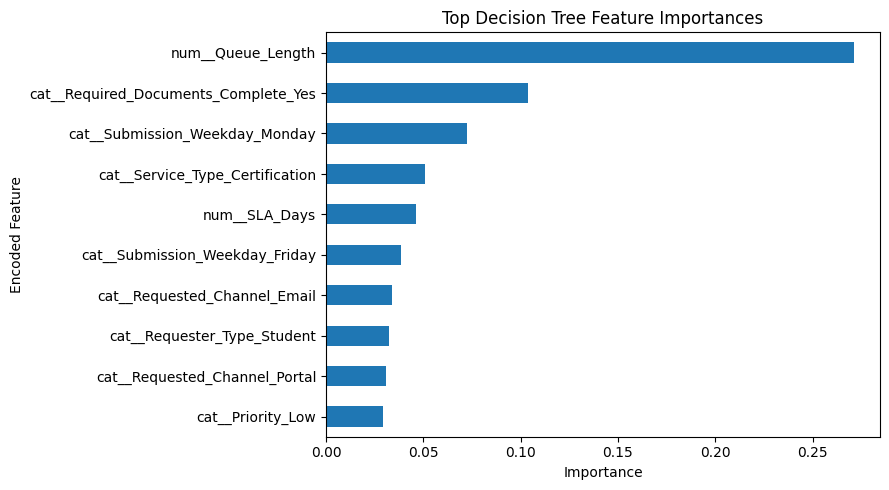

In [ ]:


fitted_preprocessor = model.named_steps["preprocessor"]
tree = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importance = tree.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

importance_df.head(10).sort_values("Importance").plot(
    kind="barh",
    x="Feature",
    y="Importance",
    legend=False,
    figsize=(9, 5)
)

plt.title("Top Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Encoded Feature")
plt.tight_layout()
plt.show()


**Tasks 11–12: Functional requirements ug UML Use Case Diagram**

**Functional Requirement 1 — Service Volume Monitoring**

The system shall display the number of student service requests by service type to help administrators identify services with high demand.

**Evidence:** [Insert the service type and request count from Task 6A.]

**Functional Requirement 2 — SLA Performance Monitoring**

The system shall display SLA breach rates by assigned office to help administrators identify offices that may require process review.

**Evidence:** [Insert the office, breach rate, and number of eligible completed requests from Task 6B.]

**Functional Requirement 3 — Delay Risk Review**

The system shall flag requests predicted to have a high risk of SLA breach for administrator review, with the prediction distinguished from observed historical facts.

**Evidence:** [Insert the test-set precision, recall, F1-score, and relevant feature-importance results from Tasks 9–10.]

**Task 12 — UML Use Case Diagram**

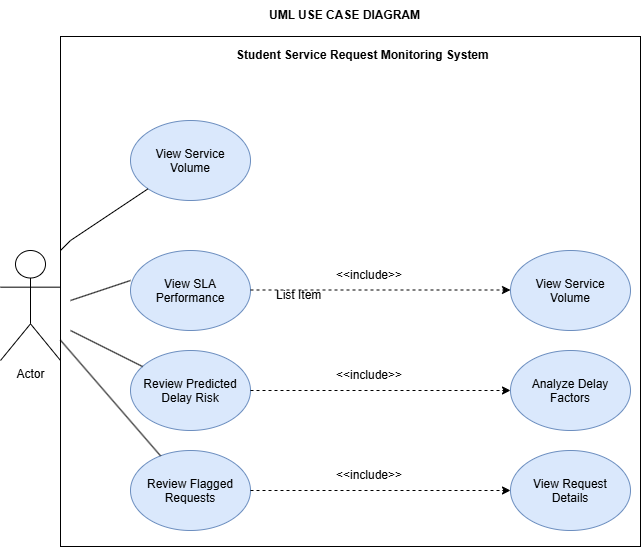

**Tasks 13–14: Administrator dashboard ug reflection**

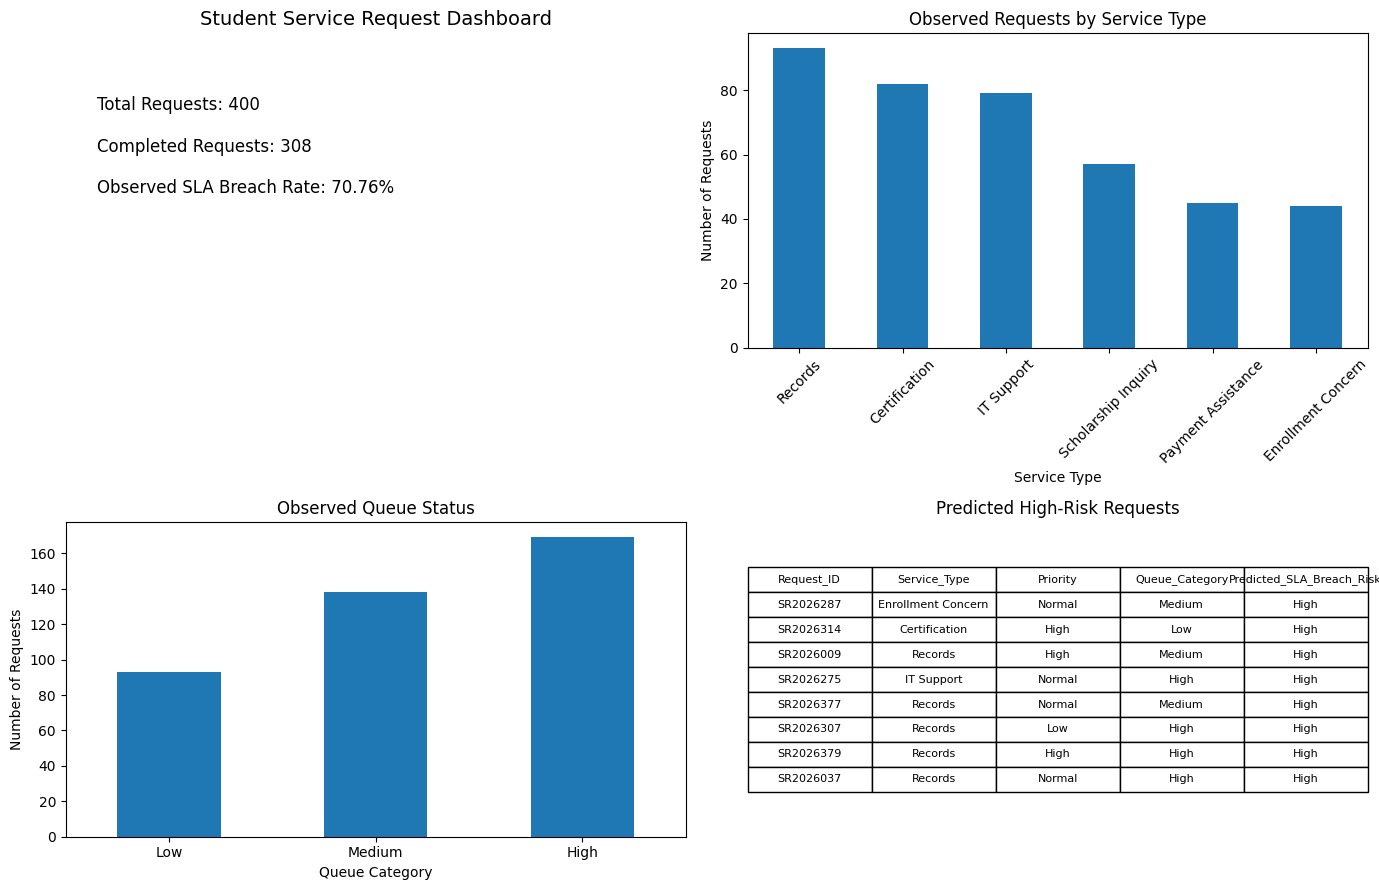

Observed SLA breach rate: 70.76 %
Predicted high-risk requests in test set: 42
High-risk predictions require administrator review.


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

total_requests = len(clean_df)

completed_requests = (
    clean_df["Status"].astype("string").str.strip().str.casefold() == "completed"
).sum()

breach_rate = (
    model_df["SLA_Breached"].mean() * 100
    if len(model_df) > 0 else 0
)

queue_counts = clean_df["Queue_Category"].value_counts().reindex(
    ["Low", "Medium", "High"], fill_value=0
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].axis("off")
axes[0, 0].set_title("Student Service Request Dashboard", fontsize=14)

axes[0, 0].text(
    0.05, 0.80,
    f"Total Requests: {total_requests}\n\n"
    f"Completed Requests: {completed_requests}\n\n"
    f"Observed SLA Breach Rate: {breach_rate:.2f}%",
    fontsize=12,
    va="top"
)

service_counts = clean_df["Service_Type"].value_counts()

service_counts.plot(
    kind="bar",
    ax=axes[0, 1],
    title="Observed Requests by Service Type"
)
axes[0, 1].set_xlabel("Service Type")
axes[0, 1].set_ylabel("Number of Requests")
axes[0, 1].tick_params(axis="x", rotation=45)

queue_counts.plot(
    kind="bar",
    ax=axes[1, 0],
    title="Observed Queue Status"
)
axes[1, 0].set_xlabel("Queue Category")
axes[1, 0].set_ylabel("Number of Requests")
axes[1, 0].tick_params(axis="x", rotation=0)

predicted_flags = X_test.loc[y_pred == 1].copy()

if "Request_ID" in model_df.columns:
    predicted_flags["Request_ID"] = model_df.loc[
        X_test.index, "Request_ID"
    ]

predicted_flags["Predicted_SLA_Breach_Risk"] = "High"

axes[1, 1].axis("off")
axes[1, 1].set_title("Predicted High-Risk Requests")

if len(predicted_flags) > 0:
    display_columns = [
        col for col in ["Request_ID", "Service_Type", "Priority",
                        "Queue_Category", "Predicted_SLA_Breach_Risk"]
        if col in predicted_flags.columns
    ]

    table_data = predicted_flags[display_columns].head(8)

    table = axes[1, 1].table(
        cellText=table_data.values,
        colLabels=table_data.columns,
        loc="center",
        cellLoc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1, 1.5)
else:
    axes[1, 1].text(
        0.05, 0.70,
        "No high-risk requests were predicted\nin the test set.",
        fontsize=11
    )

plt.tight_layout()
plt.show()

print("Observed SLA breach rate:", round(breach_rate, 2), "%")
print("Predicted high-risk requests in test set:", len(predicted_flags))
print("High-risk predictions require administrator review.")

In [ ]:


clean_df.to_csv("student_service_requests_cleaned.csv", index=False)
quality_log_df.to_csv("data_quality_log.csv", index=False)

model_df.to_csv("sla_breach_labeled_records.csv", index=False)

baseline_results.to_csv("model_evaluation.csv", index=False)

importance_df.to_csv("feature_importance.csv", index=False)

print("Output files saved successfully!")


Output files saved successfully!


In [ ]:

from google.colab import files

files.download("student_service_requests_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>